# Passau MedCo · Task 2: Random Forest Attrition Model

Same steps as [02_modeling.ipynb](02_modeling.ipynb), but with a random forest instead of XGBoost. A random forest trains many decision trees independently, each on a random sample of employees and features, and averages their votes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import randint
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, classification_report, precision_recall_curve, roc_auc_score,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

RANDOM_STATE = 42

## 1. Data and split

The data are cleaned as in the [EDA](01_eda.ipynb). The target is 1 = leaves and 0 = stays. Three constant columns and the employee ID are dropped. The split is stratified 80/20, and the test set is used only for the final evaluation.

In [2]:
employees = pd.read_csv(Path("data") / "employee-attrition.csv")
employees.columns = employees.columns.str.strip()
for column in employees.select_dtypes(include="str"):
    employees[column] = employees[column].str.strip().replace("", pd.NA)

y = employees["Attrition"].eq("Yes").astype(int)
categorical = ["BusinessTravel", "Department", "EducationField", "Gender", "JobRole", "MaritalStatus", "OverTime"]
dropped = ["Attrition", "EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"]
X = employees.drop(columns=dropped)
numeric = [column for column in X.columns if column not in categorical]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(y_train)} employees, {y_train.sum()} leavers | Test: {len(y_test)} employees, {y_test.sum()} leavers")

Train: 1176 employees, 190 leavers | Test: 294 employees, 47 leavers


## 2. Model and hyperparameters

- **Encoding:** the model needs numbers, so the categorical columns become integer codes.
- **Class imbalance:** only 16% of employees left. `class_weight="balanced"` gives leavers about five times the weight of stayers.
- **Tuning:** a randomized search tries 50 settings with stratified 5-fold cross-validation on the training set. It scores them by PR-AUC (average precision), which focuses on the rare class.

In [3]:
travel_order = ["Non-Travel", "Travel_Rarely", "Travel_Frequently"]
categories = [travel_order if column == "BusinessTravel" else sorted(X_train[column].unique()) for column in categorical]
encoder = OrdinalEncoder(categories=categories, handle_unknown="use_encoded_value", unknown_value=-1)
preprocess = ColumnTransformer([("categorical", encoder, categorical), ("numeric", "passthrough", numeric)])
model = RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1)
pipeline = Pipeline([("preprocess", preprocess), ("model", model)])

param_distributions = {
    "model__n_estimators": randint(100, 601),
    "model__max_depth": [None, 3, 5, 8, 12],
    "model__min_samples_leaf": randint(1, 21),
    "model__max_features": ["sqrt", "log2", 0.5],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = RandomizedSearchCV(
    pipeline, param_distributions, n_iter=50, scoring="average_precision", cv=cv, n_jobs=-1, random_state=RANDOM_STATE
).fit(X_train, y_train)
final_pipeline = search.best_estimator_

print(f"CV PR-AUC: {search.best_score_:.3f} ± {search.cv_results_['std_test_score'][search.best_index_]:.3f}")
pd.Series({name.removeprefix("model__"): value for name, value in search.best_params_.items()}, dtype=object)

CV PR-AUC: 0.545 ± 0.068


max_depth              8
max_features        log2
min_samples_leaf       6
n_estimators         485
dtype: object

## 3. Decision threshold

Instead of the default of 0.5, we use the threshold that maximises F1 for leavers. Each training employee is scored by a model trained on the other four folds (out-of-fold predictions), so the test set is not involved.

In [4]:
oof_scores = cross_val_predict(final_pipeline, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, oof_scores)
f1 = 2 * precision * recall / (precision + recall + 1e-12)
best = f1[:-1].argmax()
threshold = float(thresholds[best])
print(f"Threshold {threshold:.3f}: out-of-fold precision {precision[best]:.3f}, recall {recall[best]:.3f}")

Threshold 0.466: out-of-fold precision 0.463, recall 0.600


## 4. Evaluation on the test set

PR-AUC:  0.418 (chance: 0.160)
ROC-AUC: 0.787 (chance: 0.500)

Threshold 0.50
              precision    recall  f1-score   support

       Stays      0.918     0.862     0.889       247
      Leaves      0.452     0.596     0.514        47

    accuracy                          0.820       294
   macro avg      0.685     0.729     0.702       294
weighted avg      0.844     0.820     0.829       294

Threshold 0.47
              precision    recall  f1-score   support

       Stays      0.923     0.822     0.869       247
      Leaves      0.405     0.638     0.496        47

    accuracy                          0.793       294
   macro avg      0.664     0.730     0.683       294
weighted avg      0.840     0.793     0.810       294



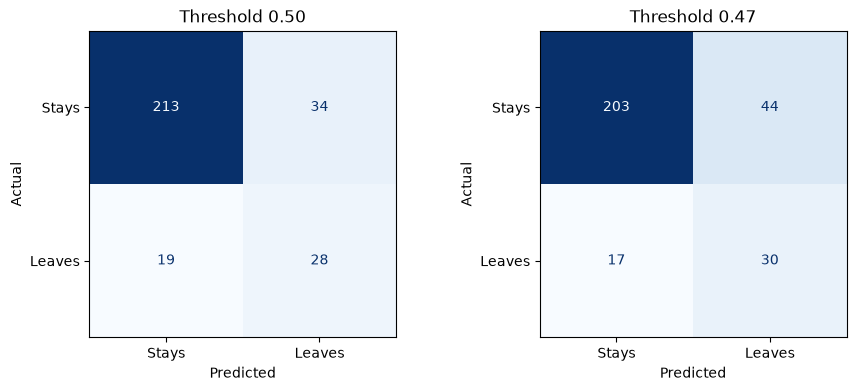

In [5]:
test_scores = final_pipeline.predict_proba(X_test)[:, 1]
print(f"PR-AUC:  {average_precision_score(y_test, test_scores):.3f} (chance: {y_test.mean():.3f})")
print(f"ROC-AUC: {roc_auc_score(y_test, test_scores):.3f} (chance: 0.500)\n")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), layout="constrained")
for ax, cutoff in zip(axes, [0.5, threshold]):
    predictions = (test_scores >= cutoff).astype(int)
    print(f"Threshold {cutoff:.2f}\n{classification_report(y_test, predictions, target_names=['Stays', 'Leaves'], digits=3)}")
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, display_labels=["Stays", "Leaves"], cmap="Blues", colorbar=False, ax=ax
    )
    ax.set(title=f"Threshold {cutoff:.2f}", xlabel="Predicted", ylabel="Actual")
plt.show()

At the optimised threshold of 0.47, the model flags 74 employees. 30 of them actually left (41% precision), and it catches 30 of 47 leavers (64% recall). At 0.5 it catches 28 of 47 leavers and raises 34 false alarms. Accuracy says little here, because always predicting "stays" already reaches 84%.

## 5. Conclusion

**Which ML algorithm did you choose and why?**
A random forest. It trains many decision trees independently, each on a random sample of employees and features, and averages their votes. Like XGBoost, it handles integer-coded categories without scaling and supports class weights, and its idea is easier to explain than boosting. However, it ranks employees clearly worse than XGBoost: its cross-validated PR-AUC is 0.545, compared with 0.638 in [02_modeling.ipynb](02_modeling.ipynb).

**What parameter settings did you use and why?**
The randomized search selected 485 trees with a maximum depth of 8, at least 6 employees per leaf and `max_features="log2"`, meaning 4 of the 30 features are considered at each split. Limiting depth and leaf size stops the trees from memorising individual employees. `class_weight="balanced"` addresses the class imbalance. The decision threshold of 0.47 maximises F1 on out-of-fold training predictions.

**Which train-test split did you use? Did you encounter problems?**
We used the same stratified 80/20 split as for XGBoost, with `random_state=42`: 1,176 training employees (190 leavers) and 294 test employees (47 leavers). Problems:
- **Class imbalance:** always predicting "stays" already gives 84% accuracy, so we used PR-AUC and class weights.
- **Small test set:** each leaver moves recall by about 2 percentage points. The test PR-AUC (0.42) is clearly below the cross-validated value (0.55).

**What is the performance of your model? Is it suitable for predicting/classifying employee attrition?**
On the test set the model reaches a PR-AUC of 0.42 (chance: 0.16) and a ROC-AUC of 0.79 (chance: 0.5). At the 0.47 threshold it catches 30 of 47 leavers with 44 false alarms. It is better than chance but noticeably weaker than XGBoost, which reaches a test PR-AUC of 0.60 and a ROC-AUC of 0.82. It can point to risk groups, but it is not reliable for individual employees.

**For management:** A random forest is easy to explain: hundreds of decision trees vote on each employee. On this data, however, it identifies employees at risk less precisely than XGBoost.